# nb02 — Scanpy QC, preprocessing, PCA, clustering and UMAP
**Questions:** Which cells and genes pass the published RNA QC thresholds?
How is expression variation organized within MCF-7 and T47D, and how does it relate
to treatment, sequencing depth and mitochondrial counts?

RNA exploration is performed independently for each cell line. ATAC is kept paired;
PCA, Leiden clusters and UMAP are **RNA-derived**, not ATAC or joint embeddings.
Clusters are exploratory groups, not cell-type or estrogen-response annotations.
Reference: [Kupp et al. (2025)](https://doi.org/10.1038/s42003-025-08533-7), Methods p.14.
This notebook does not perform differential expression, enrichment or prediction.

## 1. Mount Drive and select project paths

In [1]:
try:
    from google.colab import drive
except ImportError:
    IN_COLAB = False
else:
    IN_COLAB = True
    drive.mount('/content/drive')
from pathlib import Path
import os
BASE = Path("/content/drive/MyDrive/breast-cancer-multiome-estrogen") if IN_COLAB else Path(os.environ.get("MULTIOME_PROJECT_ROOT", Path.cwd())).resolve()
if BASE.name == "notebooks":
    BASE = BASE.parent
DATA_DIR = BASE / "data/raw/GSE154873"
RESULTS_DIR = BASE / "results"
assert (DATA_DIR / "download_manifest.json").is_file(), "Run nb00 first."
for folder in (BASE/"data/processed",RESULTS_DIR/"tables",RESULTS_DIR/"figures"):
    folder.mkdir(parents=True,exist_ok=True)
print("Project:", BASE)
print("Raw inputs:", DATA_DIR)
print("Processed outputs:", BASE/"data/processed")

Project: /home/shoko/breast-cancer-multiome-estrogen
Raw inputs: /home/shoko/breast-cancer-multiome-estrogen/data/raw/GSE154873
Processed outputs: /home/shoko/breast-cancer-multiome-estrogen/data/processed


## 2. Check the Scanpy environment

In [2]:
import importlib.util, importlib.metadata, subprocess, sys
packages = {"scanpy":"scanpy==1.11.5", "anndata":"anndata", "numpy":"numpy",
            "pandas":"pandas", "scipy":"scipy", "matplotlib":"matplotlib", "igraph":"igraph"}
missing = [package for module,package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable,"-m","pip","install",*missing])
print("Python:",sys.version)
for package in packages:
    print(package,importlib.metadata.version(package))

Python: 3.11.17 (main, Oct  7 2026, 00:02:24) [GCC 15.3.0]
scanpy 1.11.5
anndata 0.12.19
numpy 2.4.6
pandas 2.3.3
scipy 1.17.1
matplotlib 3.11.2
igraph 1.0.0


## 3. Inspect all parameters before running
**Paper thresholds:** retain genes detected in ≥3 cells and cells with ≥100 detected genes
and ≤30% mitochondrial counts. Exactly 30% passes. Apply one gene-first pass per cell line.
The exact filtering order and MT- prefix rule are documented project choices.

**Count-preserving branch:** use Scanpy calculate_qc_metrics, filter_genes, filter_cells,
log1p and scale. Preserve integer counts in layers['counts']; .X holds log1p raw counts.
All-gene scaling uses zero_center=False with stored mean/SD and offsets to stay sparse.

**Exploratory RNA branch:** copy counts, normalize_total(target_sum=10000), log1p,
highly_variable_genes(n_top_genes=2000, flavor='seurat'), center/scale only the HVGs
with clipping at 10, PCA(50), neighbors(15 neighbors, 30 PCs), Leiden(resolution=0.5),
UMAP(min_dist=0.3). Random seed=42. These choices are not asserted to reproduce the
paper's exact embeddings. Treatment labels enter plots/tables only, never the fit.
No cell-cycle regression, batch correction or cell-type annotation is applied.

In [3]:
import json
CONFIG = json.loads('{"reference_doi": "10.1038/s42003-025-08533-7", "reference_section": "Methods / Unsupervised algorithms / Standard single-cell analysis workflow, p.14", "min_cells_per_gene": 3, "min_genes_per_cell": 100, "max_pct_mitochondrial": 30.0, "mitochondrial_prefix": "MT-", "filter_order": "gene prevalence on supplied cells, then cell metrics on retained genes; one pass", "rna_transform": "log1p counts; no unspecified library-size normalization", "scaling_ddof": 1, "scaling_clip": null, "atac_cell_filter": "same RNA-selected paired cells", "atac_peak_filter": null, "atac_extra_cell_thresholds": null, "atac_layers": ["binary"], "prediction_fit_scope": "Refit feature selection/scaling/IDF on training data later", "expected": {"MCF7": {"cells": 6438, "rna_features": 36601, "atac_features": 206167}, "T47D": {"cells": 6615, "rna_features": 36601, "atac_features": 206167}}, "implementation": "Scanpy", "visualization": {"scope": "RNA only, independently per cell line; exploratory, not paper-exact", "normalize_total_target_sum": 10000.0, "hvg_flavor": "seurat", "n_top_genes": 2000, "scale_max_value": 10.0, "pca_components": 50, "neighbors_n_pcs": 30, "n_neighbors": 15, "neighbors_transformer": "sklearn", "leiden_resolution": 0.5, "leiden_flavor": "igraph", "leiden_n_iterations": 2, "umap_min_dist": 0.3, "umap_spread": 1.0, "umap_maxiter": 500, "random_state": 42}}')
print(json.dumps(CONFIG,indent=2))

{
  "reference_doi": "10.1038/s42003-025-08533-7",
  "reference_section": "Methods / Unsupervised algorithms / Standard single-cell analysis workflow, p.14",
  "min_cells_per_gene": 3,
  "min_genes_per_cell": 100,
  "max_pct_mitochondrial": 30.0,
  "mitochondrial_prefix": "MT-",
  "filter_order": "gene prevalence on supplied cells, then cell metrics on retained genes; one pass",
  "rna_transform": "log1p counts; no unspecified library-size normalization",
  "scaling_ddof": 1,
  "scaling_clip": null,
  "atac_cell_filter": "same RNA-selected paired cells",
  "atac_peak_filter": null,
  "atac_extra_cell_thresholds": null,
  "atac_layers": [
    "binary"
  ],
  "prediction_fit_scope": "Refit feature selection/scaling/IDF on training data later",
  "expected": {
    "MCF7": {
      "cells": 6438,
      "rna_features": 36601,
      "atac_features": 206167
    },
    "T47D": {
      "cells": 6615,
      "rna_features": 36601,
      "atac_features": 206167
    }
  },
  "implementation": "Scanp

## 4. Load the reusable implementation
Generated from src/qc_preprocessing.py so this notebook works without source uploads.
The explicit Scanpy calls are visible in rna_qc(), sparse_log_and_scale(), and visualize_rna().
Custom code handles TSV loading, pairing, orchestration and output validation.
Input checksums must match nb00. Full count matrices remain sparse. Only the approximately
2,000-gene visualization subset becomes dense for centered scaling.

Saved RNA files include counts/log1p representations, X_pca, X_umap, Leiden labels,
PCA loadings and neighborhood graphs. A separate *_RNA_visualization.h5ad contains the
scaled HVG input plus raw-count and normalized-log layers.
ATAC retains all supplied peaks and the identical RNA-selected cells.
Re-running replaces derived files atomically per file; raw archives remain unchanged.

In [4]:
"""Scanpy QC, paired preprocessing, and exploratory RNA PCA/Leiden/UMAP."""
import gc
import gzip
import hashlib
import json
import warnings
import copy
import importlib.metadata
import scanpy as sc
from array import array
from datetime import datetime, timezone
from pathlib import Path
import anndata as ad
import numpy as np
import pandas as pd
from scipy import sparse

def file_hash(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

def read_sparse_counts(path):
    """Parse one dense-text row at a time, then transpose verified features x cells."""
    values, indices, indptr = array("i"), array("i"), array("q", [0])
    features = []
    with gzip.open(path, "rt") as f:
        cells = f.readline().rstrip("\r\n").split("\t")
        if not cells or any(not cell for cell in cells) or len(set(cells)) != len(cells):
            raise ValueError(f"Missing or duplicate cell IDs in {path}")
        for line_number, line in enumerate(f, start=2):
            feature, sep, text = line.rstrip("\r\n").partition("\t")
            if not sep or text.count("\t") + 1 != len(cells):
                raise ValueError(f"Unexpected row width at {path}:{line_number}")
            with warnings.catch_warnings():
                warnings.simplefilter("error", DeprecationWarning)
                row = np.fromstring(text, sep="\t", dtype=np.float64)
            if (row.size != len(cells) or not np.isfinite(row).all() or
                    (row < 0).any() or (row != np.floor(row)).any() or
                    (row > np.iinfo(np.int32).max).any()):
                raise ValueError(f"Invalid integer counts at {path}:{line_number}")
            nz = np.flatnonzero(row)
            values.frombytes(row[nz].astype(np.int32).tobytes())
            indices.frombytes(nz.astype(np.int32).tobytes())
            indptr.append(len(values))
            features.append(feature)
            if len(features) % 25000 == 0:
                print(f"  {Path(path).name}: {len(features):,} features", flush=True)
    if not features or len(features) != len(set(features)) or any(not x for x in features):
        raise ValueError(f"Missing or duplicated feature IDs: {path}")
    matrix = sparse.csr_matrix((np.frombuffer(values, dtype=np.int32),
                               np.frombuffer(indices, dtype=np.int32),
                               np.frombuffer(indptr, dtype=np.int64)),
                              shape=(len(features), len(cells))).T.tocsr()
    return matrix, pd.Index(cells, name="cell_id"), pd.Index(features, name="feature_id")

def read_metadata(path, expected_cells, cell_line):
    frame = pd.read_csv(path, sep="\t", header=None, dtype=str, keep_default_na=False)
    if frame.shape[1] != 2:
        raise ValueError("Expected the inspected two-column headerless metadata.")
    frame.columns = ["cell_id", "sample_label"]
    if frame.cell_id.duplicated().any() or not frame.cell_id.tolist() == list(expected_cells):
        raise ValueError("Metadata cells/order do not exactly match the count matrix.")
    frame = frame.set_index("cell_id")
    mapping = {"YW_si_Control_plus_E2": "E2", "YW_si_Control_plus_Veh": "Vehicle"}
    if not set(frame.sample_label).issubset(mapping):
        raise ValueError("Unrecognized treatment labels.")
    frame["treatment"] = frame.sample_label.map(mapping)
    frame["cell_line"] = cell_line
    frame["global_cell_id"] = cell_line + ":" + frame.index
    return frame


def rna_qc(counts, genes, config):
    """Use Scanpy QC and filter APIs, preserving the documented gene-first order."""
    original = ad.AnnData(X=counts, var=pd.DataFrame(index=genes))
    original.var["mt"] = original.var_names.str.startswith(config["mitochondrial_prefix"])
    if not original.var["mt"].any():
        raise ValueError("No mitochondrial genes detected; verify gene naming before QC.")
    sc.pp.calculate_qc_metrics(original, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)
    gene_keep, gene_detected = sc.pp.filter_genes(
        original, min_cells=config["min_cells_per_gene"], inplace=False)
    selected = original[:, gene_keep].copy()
    sc.pp.calculate_qc_metrics(selected, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)
    keep_genes, _ = sc.pp.filter_cells(
        selected, min_genes=config["min_genes_per_cell"], inplace=False)
    pct_mt = selected.obs["pct_counts_mt"].to_numpy()
    keep_mt = np.isfinite(pct_mt) & (pct_mt <= config["max_pct_mitochondrial"])
    qc = pd.DataFrame({
        "rna_total_counts_before_gene_filter": original.obs["total_counts"].to_numpy(),
        "rna_n_genes_before_gene_filter": original.obs["n_genes_by_counts"].to_numpy(),
        "rna_total_counts": selected.obs["total_counts"].to_numpy(),
        "rna_n_genes": selected.obs["n_genes_by_counts"].to_numpy(),
        "rna_pct_counts_mt": pct_mt,
        "pass_min_genes": keep_genes, "pass_max_pct_mt": keep_mt,
        "pass_rna_qc": keep_genes & keep_mt})
    var = pd.DataFrame({"n_cells_detected_before_qc": gene_detected,
                        "pass_min_cells": gene_keep,
                        "mt": original.var["mt"].to_numpy()}, index=genes)
    return keep_genes & keep_mt, gene_keep, qc, var


def sparse_log_and_scale(counts, ddof=1):
    """Use Scanpy log1p/scale; store centering offsets to keep all-gene data sparse."""
    if ddof != 1:
        raise ValueError("This workflow uses Scanpy's sample-standard-deviation scaling.")
    if counts.shape[0] <= 1:
        raise ValueError("Too few cells to estimate scaling variance.")
    transformed = ad.AnnData(X=counts.astype(np.float64))
    sc.pp.log1p(transformed)
    log = transformed.X.copy()
    sc.pp.scale(transformed, zero_center=False, max_value=None)
    if not np.isfinite(transformed.X.data).all():
        raise ValueError("Scanpy scaling returned nonfinite values.")
    return log.astype(np.float32), transformed.X.astype(np.float32).tocsr(), transformed.var["mean"].to_numpy(), transformed.var["std"].to_numpy()

def centered_scaled_block(adata, rows, columns):
    """Materialize only an explicitly requested small block of centered z-scores."""
    block = adata.layers["scaled_no_center"][rows, :][:, columns]
    if block.shape[0] * block.shape[1] > 5_000_000:
        raise ValueError("Request a smaller block; full centered matrices are not materialized.")
    offset = adata.var["scale_center_offset"].to_numpy()[columns]
    return block.toarray() - offset

def save_h5ad(adata, path):
    path = Path(path)
    temp = path.with_name(path.stem + ".partial.h5ad")
    adata.write_h5ad(temp, compression="gzip")
    check = ad.read_h5ad(temp, backed="r")
    try:
        if check.shape != adata.shape or not check.obs_names.equals(adata.obs_names):
            raise ValueError(f"Written AnnData validation failed: {path}")
    finally:
        check.file.close()
    temp.replace(path)

def qc_figure(qc, cell_line, config, output):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), constrained_layout=True)
    for ax, col, title in zip(axes, ["rna_n_genes", "rna_pct_counts_mt", "atac_n_peaks"],
                             ["Detected RNA genes", "Mitochondrial RNA (%)", "Detected ATAC peaks"]):
        edges = np.histogram_bin_edges(qc[col].dropna(), bins=50)
        ax.hist(qc[col], bins=edges, color="#aebbc9", label="All supplied cells")
        ax.hist(qc.loc[qc.pass_rna_qc, col], bins=edges, histtype="step", linewidth=1.8,
                color="#176b63", label="RNA QC retained")
        ax.set_title(title)
        ax.set_ylabel("Cells")
    axes[0].axvline(config["min_genes_per_cell"], color="#bd4b35", linestyle="--")
    axes[1].axvline(config["max_pct_mitochondrial"], color="#bd4b35", linestyle="--")
    axes[2].legend(fontsize=8)
    fig.suptitle(f"{cell_line}: paper-guided QC; ATAC follows the same cell mask")
    fig.savefig(output, dpi=160)
    plt.close(fig)


def visualize_rna(rna, root, cell_line, config):
    """Fit RNA-only descriptive embeddings; treatment labels do not enter fitting."""
    settings = config["visualization"]
    seed = settings["random_state"]
    viz = ad.AnnData(X=rna.layers["counts"].astype(np.float32), obs=rna.obs.copy(),
                    var=pd.DataFrame(index=rna.var_names.copy()))
    sc.pp.normalize_total(viz, target_sum=settings["normalize_total_target_sum"])
    sc.pp.log1p(viz)
    sc.pp.highly_variable_genes(viz, n_top_genes=settings["n_top_genes"],
                               flavor=settings["hvg_flavor"], subset=False)
    mask = viz.var["highly_variable"].to_numpy()
    rna.var["highly_variable"] = mask
    viz.var.to_csv(Path(root)/"results/tables"/f"{cell_line}_hvg.tsv",
                   sep="\t", lineterminator="\n")
    viz = viz[:, mask].copy()
    viz.layers["counts"] = rna.layers["counts"][:, mask].copy()
    viz.layers["log1p_normalized"] = viz.X.copy()
    # Only the ~2,000-HVG visualization subset is centered/densified.
    viz.X = viz.X.astype(np.float64)
    sc.pp.scale(viz, zero_center=True, max_value=settings["scale_max_value"])
    if not np.isfinite(viz.X).all():
        raise ValueError("Scanpy HVG scaling returned nonfinite values.")
    sc.pp.pca(viz, n_comps=settings["pca_components"], svd_solver="arpack",
              random_state=seed, mask_var=None)
    sc.pp.neighbors(viz, n_neighbors=settings["n_neighbors"],
                    n_pcs=settings["neighbors_n_pcs"], use_rep="X_pca",
                    transformer=settings["neighbors_transformer"], random_state=seed)
    sc.tl.leiden(viz, resolution=settings["leiden_resolution"], random_state=seed,
                 flavor=settings["leiden_flavor"], n_iterations=settings["leiden_n_iterations"],
                 directed=False, key_added="leiden")
    sc.tl.umap(viz, min_dist=settings["umap_min_dist"], spread=settings["umap_spread"],
               maxiter=settings["umap_maxiter"], random_state=seed)
    viz.uns["visualization"] = copy.deepcopy(settings)
    viz.uns["visualization"]["interpretation"] = "RNA-derived exploratory clusters, not cell types or predictions"
    rna.obs["leiden"] = viz.obs["leiden"].copy()
    rna.obsm["X_pca"] = viz.obsm["X_pca"].copy()
    rna.obsm["X_umap"] = viz.obsm["X_umap"].copy()
    rna.varm["PCs"] = np.zeros((rna.n_vars, viz.varm["PCs"].shape[1]), dtype=np.float32)
    rna.varm["PCs"][mask] = viz.varm["PCs"]
    for key in ("pca", "neighbors", "umap", "leiden", "visualization"):
        rna.uns[key] = copy.deepcopy(viz.uns[key])
    for key in ("connectivities", "distances"):
        rna.obsp[key] = viz.obsp[key].copy()
    tables, figures = Path(root)/"results/tables", Path(root)/"results/figures"
    summary = pd.crosstab(viz.obs["leiden"], viz.obs["treatment"], dropna=False)
    summary.to_csv(tables/f"{cell_line}_cluster_treatment_counts.tsv",sep="\t",lineterminator="\n")
    embedding = viz.obs[["treatment","leiden"]].copy()
    embedding["UMAP1"], embedding["UMAP2"] = viz.obsm["X_umap"].T
    for i in range(viz.obsm["X_pca"].shape[1]):
        embedding[f"PC{i+1}"] = viz.obsm["X_pca"][:, i]
    embedding.to_csv(tables/f"{cell_line}_rna_embeddings.tsv",sep="\t",lineterminator="\n")
    save_h5ad(viz, Path(root)/"data/processed"/f"{cell_line}_RNA_visualization.h5ad")
    import matplotlib.pyplot as plt
    sc.set_figure_params(dpi=100, dpi_save=160, fontsize=10, frameon=False)
    colors = ["treatment", "leiden", "rna_total_counts", "rna_pct_counts_mt"]
    labels = ["Treatment", "Leiden cluster", "RNA counts", "Mitochondrial RNA (%)"]
    for name, plot in (("pca",sc.pl.pca), ("umap",sc.pl.umap)):
        fig = plot(viz, color=colors, title=[f"{cell_line}: {x}" for x in labels],
                   ncols=2, show=False, return_fig=True, size=8, wspace=0.35)
        fig.savefig(figures/f"{cell_line}_rna_{name}.png",dpi=160,bbox_inches="tight")
        plt.close(fig)
    sc.pl.pca_variance_ratio(viz, n_pcs=settings["pca_components"], log=False, show=False)
    plt.gcf().savefig(figures/f"{cell_line}_pca_variance.png",dpi=160,bbox_inches="tight")
    plt.close()
    result = {"n_hvgs": int(mask.sum()), "n_pcs": int(viz.obsm["X_pca"].shape[1]),
              "n_clusters": int(viz.obs["leiden"].nunique()),
              "cluster_sizes": {str(k):int(v) for k,v in viz.obs["leiden"].value_counts().items()},
              "pca_variance_first_30": float(viz.uns["pca"]["variance_ratio"][:settings["neighbors_n_pcs"]].sum()),
              "parameters": settings}
    del viz
    gc.collect()
    return result

def preprocess_line(root, cell_line, config):
    root = Path(root)
    raw = root / "data/raw/GSE154873"
    output = root / "data/processed"
    tables, figures = root / "results/tables", root / "results/figures"
    for folder in (output, tables, figures):
        folder.mkdir(parents=True, exist_ok=True)
    prefix = f"GSE154873_{cell_line}_multiome_"
    sources = {name: raw / (prefix + suffix + ".tsv.gz") for name, suffix in
               (("rna", "RNA_counts"), ("atac", "ATAC_counts"), ("metadata", "metadata"))}
    manifest = json.loads((raw / "download_manifest.json").read_text())
    source_hashes = {}
    for name, path in sources.items():
        source_hashes[name] = file_hash(path)
        if source_hashes[name] != manifest["files"][f"{cell_line.lower()}_{name}"]["sha256"]:
            raise ValueError(f"Input differs from inspected download: {path}")
    print(f"\n{cell_line}: reading RNA", flush=True)
    counts, cells, genes = read_sparse_counts(sources["rna"])
    expected = config["expected"][cell_line]
    if counts.shape != (expected["cells"], expected["rna_features"]):
        raise ValueError("RNA dimensions differ from inspected paper dataset.")
    obs = read_metadata(sources["metadata"], cells, cell_line)
    cell_keep, gene_keep, qc, var = rna_qc(counts, genes, config)
    qc.index = cells
    qc = obs.join(qc)
    if not cell_keep.any():
        raise ValueError("QC retained no cells.")
    kept_counts = counts[cell_keep, :][:, gene_keep].tocsr()
    del counts
    log, scaled, mean, std = sparse_log_and_scale(kept_counts, config["scaling_ddof"])
    rna = ad.AnnData(X=log, obs=qc.loc[cell_keep].copy(), var=var.loc[gene_keep].copy())
    rna.layers["counts"] = kept_counts
    rna.layers["scaled_no_center"] = scaled
    rna.var["log1p_mean"] = mean
    rna.var["log1p_std"] = std
    rna.var["scale_center_offset"] = mean / std
    rna.uns["preprocessing"] = {
        "reference_doi": config["reference_doi"], "config_json": json.dumps(config),
        "X": "log1p(raw counts), no library-size normalization",
        "counts": "Unmodified integer counts for retained cells and genes",
        "centered_scale": "scaled_no_center - var.scale_center_offset",
        "scale_scope": "descriptive per cell line; refit inside future training folds",
        "filter_order": config["filter_order"], "source_sha256_json": json.dumps(source_hashes)}
    rna.uns["log1p"] = {"base": None}
    print(f"{cell_line}: Scanpy HVGs, PCA, neighbors, Leiden and UMAP", flush=True)
    visualization = visualize_rna(rna, root, cell_line, config)
    qc["leiden"] = pd.Series(rna.obs["leiden"].astype(str), index=rna.obs_names).reindex(qc.index).fillna("excluded")
    rna_path = output / f"{cell_line}_RNA_paper_qc.h5ad"
    save_h5ad(rna, rna_path)
    del rna, kept_counts, log, scaled
    gc.collect()
    print(f"{cell_line}: reading paired ATAC", flush=True)
    atac_counts, atac_cells, peaks = read_sparse_counts(sources["atac"])
    if atac_counts.shape != (expected["cells"], expected["atac_features"]) or not atac_cells.equals(cells):
        raise ValueError("ATAC dimensions or exact cell order differ from RNA.")
    qc["atac_total_peak_counts"] = np.asarray(atac_counts.sum(axis=1)).ravel()
    qc["atac_n_peaks"] = np.diff(atac_counts.indptr)
    qc["atac_zero_counts"] = qc.atac_total_peak_counts == 0
    selected = atac_counts[cell_keep].tocsr()
    del atac_counts
    atac_var = pd.DataFrame(index=peaks)
    coordinates = [peak.rsplit("-", 2) for peak in peaks]
    if any(len(x) != 3 or not x[1].isdigit() or not x[2].isdigit() or int(x[1]) >= int(x[2])
           for x in coordinates):
        raise ValueError("Unrecognized peak coordinates.")
    atac_var["contig"] = [x[0] for x in coordinates]
    atac_var["start_as_supplied"] = [int(x[1]) for x in coordinates]
    atac_var["end_as_supplied"] = [int(x[2]) for x in coordinates]
    atac_var["n_cells_detected_after_rna_qc"] = np.asarray((selected > 0).sum(axis=0)).ravel()
    atac = ad.AnnData(X=selected, obs=qc.loc[cell_keep].copy(), var=atac_var)
    binary = selected.astype(np.uint8)
    binary.data[:] = 1
    atac.layers["binary"] = binary
    atac.uns["preprocessing"] = {
        "reference_doi": config["reference_doi"], "config_json": json.dumps(config),
        "X": "Unmodified integer ATAC peak counts for RNA-QC retained cells; all supplied peaks",
        "binary": "1 for count > 0, otherwise 0",
        "qc_limit": "RNA cell mask only; no fragment-level metrics or ATAC-specific thresholds available",
        "coordinates": "As supplied; genome build and coordinate origin unresolved",
        "source_sha256_json": json.dumps(source_hashes)}
    atac_path = output / f"{cell_line}_ATAC_paired_paper_qc.h5ad"
    save_h5ad(atac, atac_path)
    qc.to_csv(tables / f"{cell_line}_cell_qc.tsv", sep="\t", lineterminator="\n")
    var.to_csv(tables / f"{cell_line}_gene_qc.tsv", sep="\t", lineterminator="\n")
    qc_figure(qc, cell_line, config, figures / f"{cell_line}_paper_qc.png")
    summary = {
        "cells_before": len(cells), "cells_after": int(cell_keep.sum()),
        "genes_before": len(genes), "genes_after": int(gene_keep.sum()),
        "atac_peaks_before": len(peaks), "atac_peaks_after": len(peaks),
        "fail_min_genes": int((~qc.pass_min_genes).sum()),
        "fail_max_pct_mt": int((~qc.pass_max_pct_mt).sum()),
        "fail_both": int(((~qc.pass_min_genes) & (~qc.pass_max_pct_mt)).sum()),
        "atac_zero_count_cells_retained": int(qc.loc[cell_keep, "atac_zero_counts"].sum()),
        "treatment_before": {k:int(v) for k,v in qc.treatment.value_counts().items()},
        "treatment_after": {k:int(v) for k,v in qc.loc[cell_keep].treatment.value_counts().items()},
        "source_sha256": source_hashes, "exact_paired_order": True,
        "visualization": visualization,
        "scanpy_version": importlib.metadata.version("scanpy"),
        "outputs": [str(rna_path.relative_to(root)), str(atac_path.relative_to(root)), f"data/processed/{cell_line}_RNA_visualization.h5ad"]}
    saved_rna, saved_atac = ad.read_h5ad(rna_path, backed="r"), ad.read_h5ad(atac_path, backed="r")
    try:
        if not saved_rna.obs_names.equals(saved_atac.obs_names):
            raise ValueError("Written RNA/ATAC cells no longer match.")
    finally:
        saved_rna.file.close()
        saved_atac.file.close()
    print(json.dumps(summary, indent=2), flush=True)
    del atac, selected, binary
    gc.collect()
    return summary

def run_preprocessing(root, config):
    report = {"reference_doi": config["reference_doi"], "config": config,
              "run_at_utc": datetime.now(timezone.utc).isoformat(), "cell_lines": {}}
    for cell_line in ("MCF7", "T47D"):
        report["cell_lines"][cell_line] = preprocess_line(root, cell_line, config)
    destination = Path(root) / "results/tables/paper_qc_summary.json"
    destination.write_text(json.dumps(report, indent=2) + "\n")
    return report

In [5]:
sc.settings.verbosity = 2
report = {"reference_doi": CONFIG["reference_doi"], "config": CONFIG,
          "run_at_utc": datetime.now(timezone.utc).isoformat(), "cell_lines": {}}
from IPython.display import Image, display

## 5. MCF7: QC → RNA preprocessing → PCA → neighbors → Leiden → UMAP
Checksums → load counts/metadata → Scanpy gene filter → Scanpy cell QC/filter →
mitochondrial cutoff → preserve counts/log1p → normalized RNA HVGs →
center/scale HVGs → PCA → neighbors → Leiden → UMAP → same cell mask for ATAC.
This cell streams the original TSVs and may take several minutes in Colab.

In [6]:
report["cell_lines"]["MCF7"] = preprocess_line(BASE, "MCF7", CONFIG)


MCF7: reading RNA


  GSE154873_MCF7_multiome_RNA_counts.tsv.gz: 25,000 features


filtered out 11496 genes that are detected in less than 3 cells


MCF7: Scanpy HVGs, PCA, neighbors, Leiden and UMAP


normalizing counts per cell


...

  GSE154873_MCF7_multiome_ATAC_counts.tsv.gz: 125,000 features


  GSE154873_MCF7_multiome_ATAC_counts.tsv.gz: 150,000 features


  GSE154873_MCF7_multiome_ATAC_counts.tsv.gz: 175,000 features


  GSE154873_MCF7_multiome_ATAC_counts.tsv.gz: 200,000 features


{
  "cells_before": 6438,
  "cells_after": 6019,
  "genes_before": 36601,
  "genes_after": 25105,
  "atac_peaks_before": 206167,
  "atac_peaks_after": 206167,
  "fail_min_genes": 0,
  "fail_max_pct_mt": 419,
  "fail_both": 0,
  "atac_zero_count_cells_retained": 0,
  "treatment_before": {
    "E2": 3443,
    "Vehicle": 2995
  },
  "treatment_after": {
    "E2": 3289,
    "Vehicle": 2730
  },
  "source_sha256": {
    "rna": "f9db7d5250502cceeca67c172eecb833d1c77772650636482f4560b00946915d",
    "atac": "80aacae2e0e84ec2268e3dc7b4450aec79e5438aeec8d9fc15ea009c236c59f4",
    "metadata": "74184cef431939af755f1555fd44d0f25b292a2e0a6ba5663ad574d5609e9a7c"
  },
  "exact_paired_order": true,
  "visualization": {
    "n_hvgs": 2000,
    "n_pcs": 50,
    "n_clusters": 9,
    "cluster_sizes": {
      "4": 2179,
      "3": 1262,
      "0": 1206,
      "2": 452,
      "5": 354,
      "6": 255,
      "1": 177,
      "7": 107,
      "8": 27
    },
    "pca_variance_first_30": 0.16049416630280175,
    

{
  "cells_before": 6438,
  "cells_after": 6019,
  "genes_before": 36601,
  "genes_after": 25105,
  "atac_peaks_before": 206167,
  "atac_peaks_after": 206167,
  "fail_min_genes": 0,
  "fail_max_pct_mt": 419,
  "fail_both": 0,
  "atac_zero_count_cells_retained": 0,
  "treatment_before": {
    "E2": 3443,
    "Vehicle": 2995
  },
  "treatment_after": {
    "E2": 3289,
    "Vehicle": 2730
  },
  "source_sha256": {
    "rna": "f9db7d5250502cceeca67c172eecb833d1c77772650636482f4560b00946915d",
    "atac": "80aacae2e0e84ec2268e3dc7b4450aec79e5438aeec8d9fc15ea009c236c59f4",
    "metadata": "74184cef431939af755f1555fd44d0f25b292a2e0a6ba5663ad574d5609e9a7c"
  },
  "exact_paired_order": true,
  "visualization": {
    "n_hvgs": 2000,
    "n_pcs": 50,
    "n_clusters": 9,
    "cluster_sizes": {
      "4": 2179,
      "3": 1262,
      "0": 1206,
      "2": 452,
      "5": 354,
      "6": 255,
      "1": 177,
      "7": 107,
      "8": 27
    },
    "pca_variance_first_30": 0.16049416630280175,
    

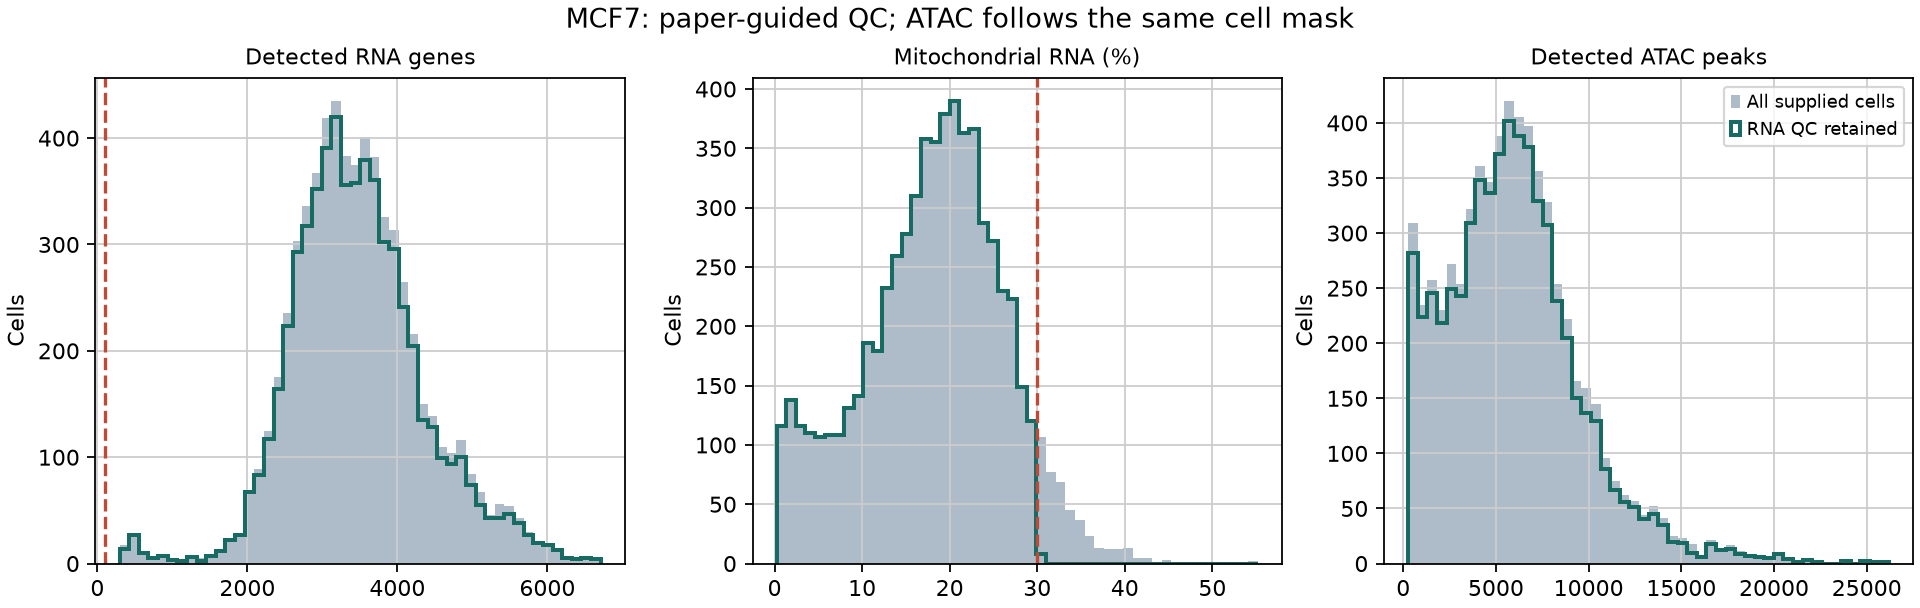

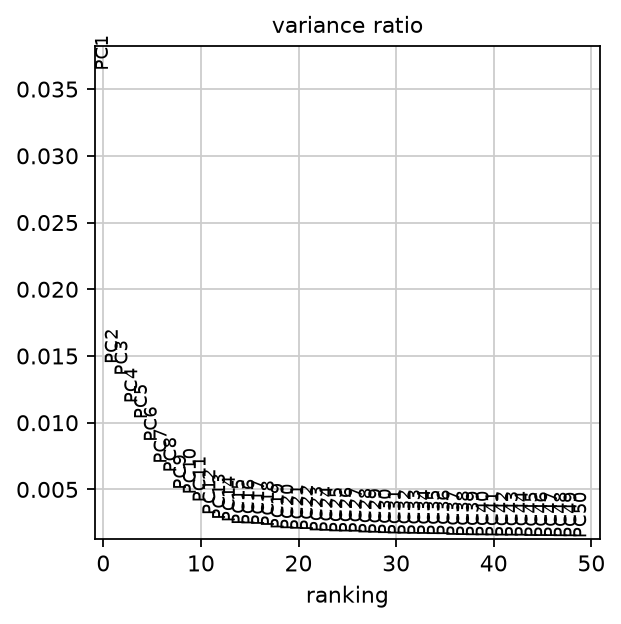

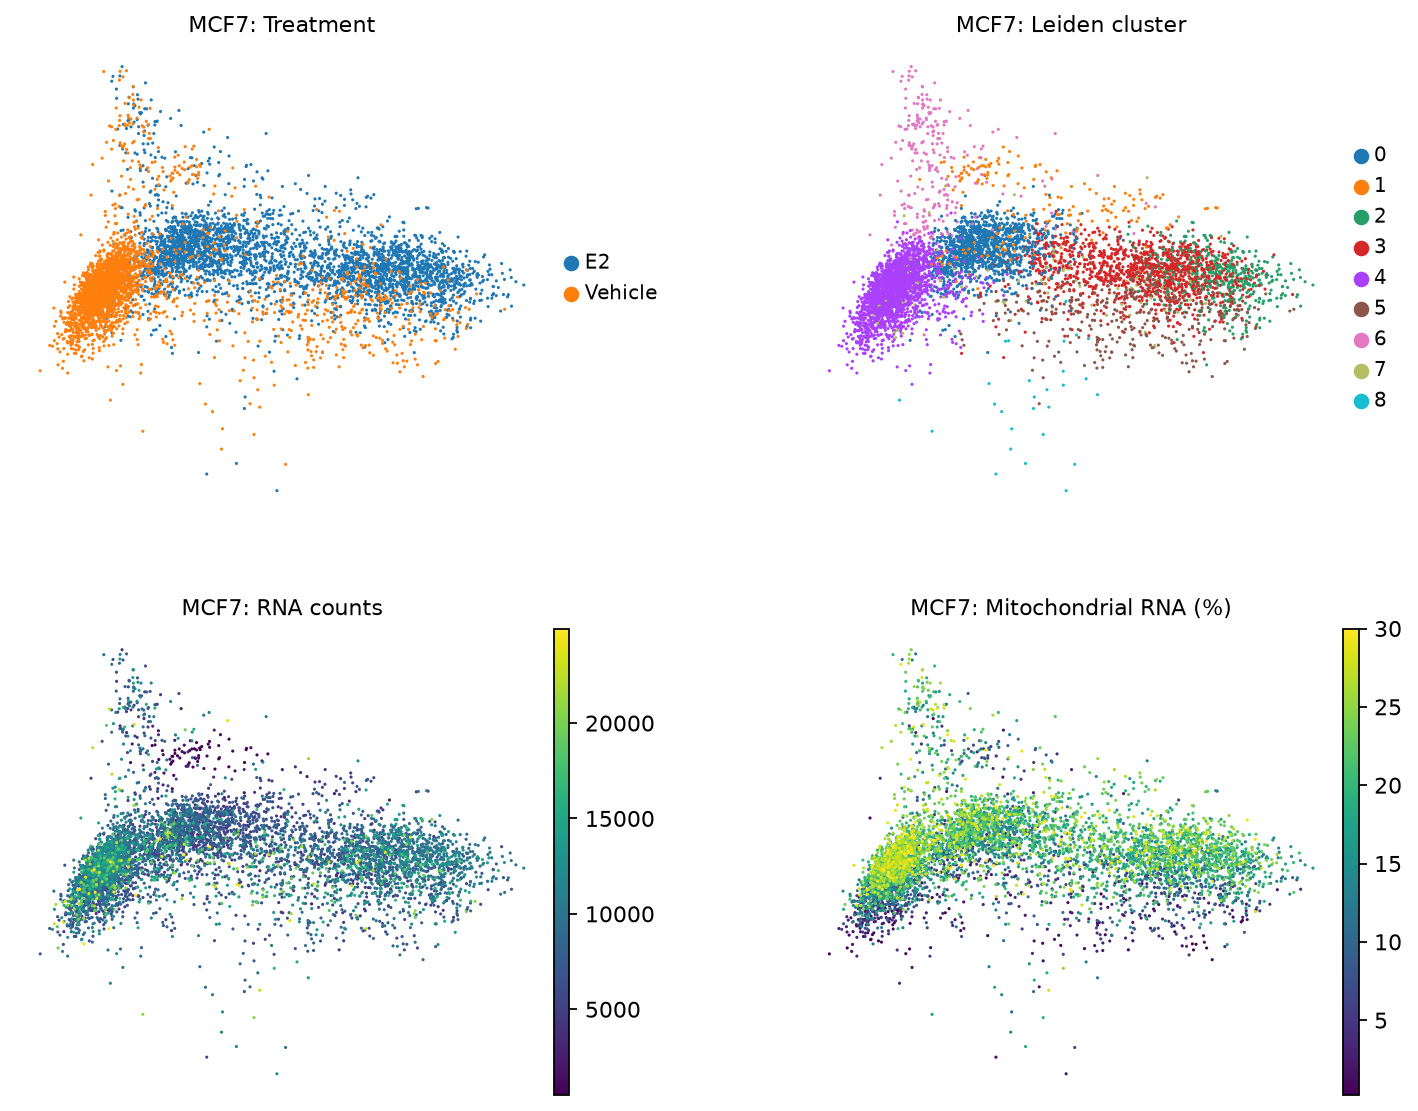

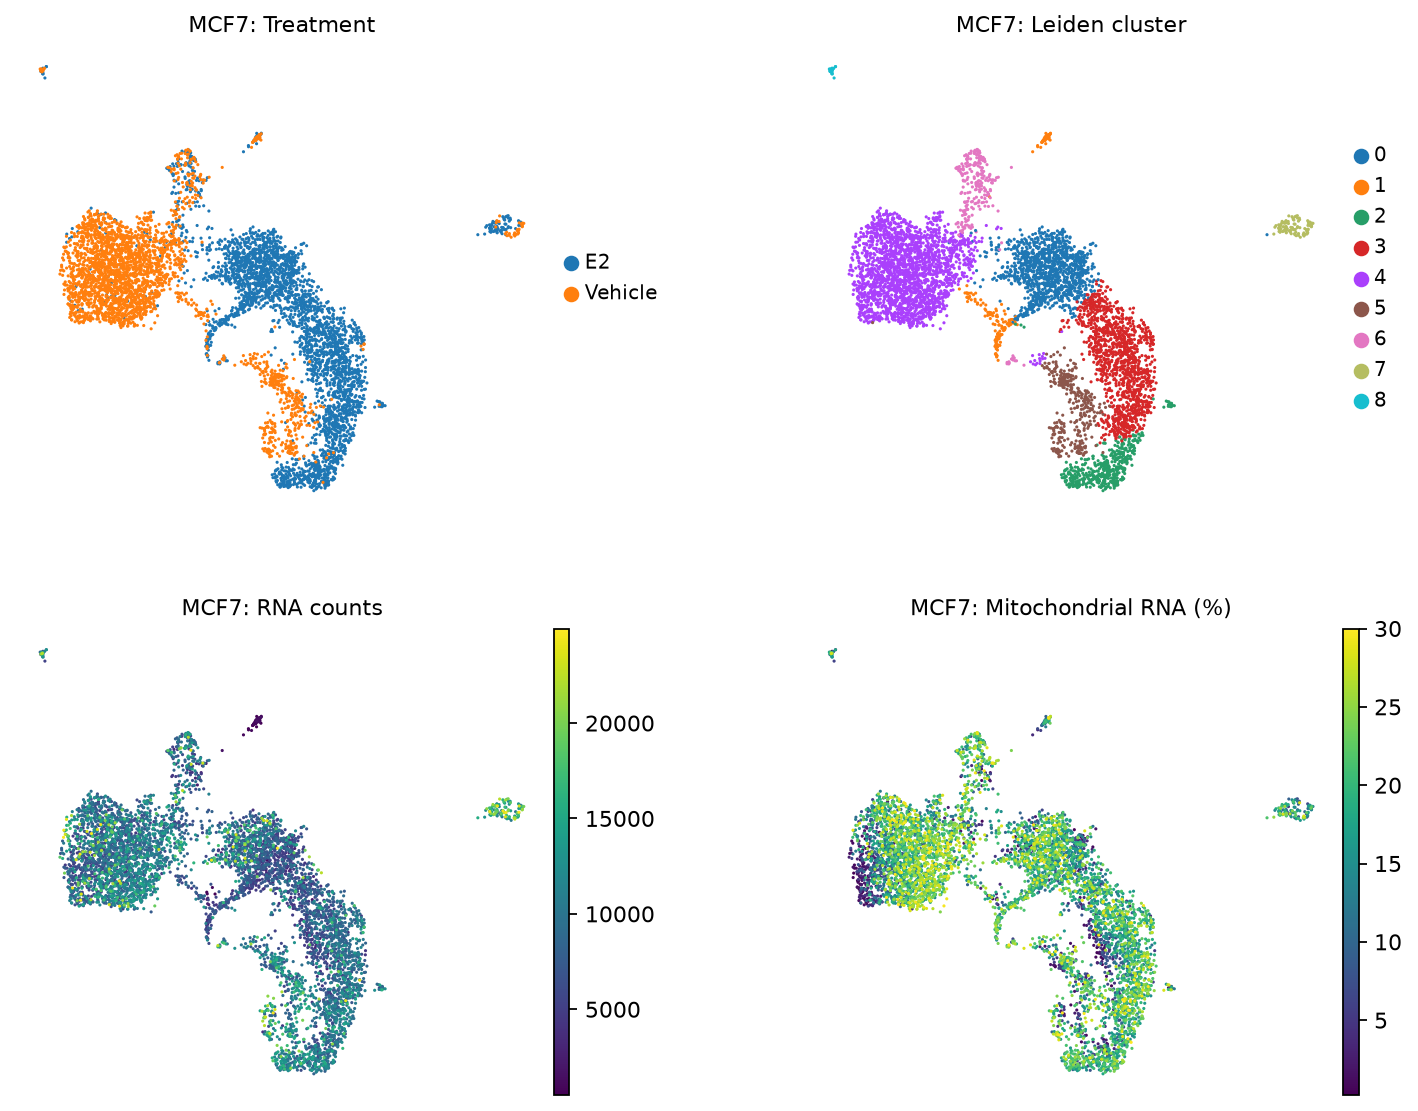

,leiden,E2,Vehicle
0,0,1203,3
1,1,89,88
2,2,444,8
3,3,1249,13
4,4,80,2099
5,5,14,340
6,6,126,129
7,7,72,35
8,8,12,15


In [7]:
print(json.dumps(report["cell_lines"]["MCF7"],indent=2))
for suffix in ("paper_qc","pca_variance","rna_pca","rna_umap"):
    display(Image(filename=str(RESULTS_DIR/"figures"/f"MCF7_{suffix}.png")))
display(pd.read_csv(RESULTS_DIR/"tables"/"MCF7_cluster_treatment_counts.tsv",sep="\t"))

## 6. T47D: QC → RNA preprocessing → PCA → neighbors → Leiden → UMAP
Checksums → load counts/metadata → Scanpy gene filter → Scanpy cell QC/filter →
mitochondrial cutoff → preserve counts/log1p → normalized RNA HVGs →
center/scale HVGs → PCA → neighbors → Leiden → UMAP → same cell mask for ATAC.
This cell streams the original TSVs and may take several minutes in Colab.

In [8]:
report["cell_lines"]["T47D"] = preprocess_line(BASE, "T47D", CONFIG)


T47D: reading RNA


  GSE154873_T47D_multiome_RNA_counts.tsv.gz: 25,000 features


filtered out 10281 genes that are detected in less than 3 cells


T47D: Scanpy HVGs, PCA, neighbors, Leiden and UMAP


normalizing counts per cell


...

  GSE154873_T47D_multiome_ATAC_counts.tsv.gz: 125,000 features


  GSE154873_T47D_multiome_ATAC_counts.tsv.gz: 150,000 features


  GSE154873_T47D_multiome_ATAC_counts.tsv.gz: 175,000 features


  GSE154873_T47D_multiome_ATAC_counts.tsv.gz: 200,000 features


{
  "cells_before": 6615,
  "cells_after": 6562,
  "genes_before": 36601,
  "genes_after": 26320,
  "atac_peaks_before": 206167,
  "atac_peaks_after": 206167,
  "fail_min_genes": 0,
  "fail_max_pct_mt": 53,
  "fail_both": 0,
  "atac_zero_count_cells_retained": 0,
  "treatment_before": {
    "E2": 3587,
    "Vehicle": 3028
  },
  "treatment_after": {
    "E2": 3565,
    "Vehicle": 2997
  },
  "source_sha256": {
    "rna": "576f0d067d91f8e435b4bd3fa47cb1cbc541d724293965ad629dd52047f3004f",
    "atac": "6c72f18ef3fcf49e7a4d5971e6aa4073b4982c8c1ab8a8e9ed810e2ab954bce7",
    "metadata": "e36d108ab2aae925007f0d5dee10cba8a2be0308aac0570a4109f54903bca542"
  },
  "exact_paired_order": true,
  "visualization": {
    "n_hvgs": 2000,
    "n_pcs": 50,
    "n_clusters": 8,
    "cluster_sizes": {
      "1": 1924,
      "4": 1398,
      "2": 1195,
      "0": 570,
      "5": 452,
      "6": 432,
      "3": 320,
      "7": 271
    },
    "pca_variance_first_30": 0.15321452146431014,
    "parameters": {


{
  "cells_before": 6615,
  "cells_after": 6562,
  "genes_before": 36601,
  "genes_after": 26320,
  "atac_peaks_before": 206167,
  "atac_peaks_after": 206167,
  "fail_min_genes": 0,
  "fail_max_pct_mt": 53,
  "fail_both": 0,
  "atac_zero_count_cells_retained": 0,
  "treatment_before": {
    "E2": 3587,
    "Vehicle": 3028
  },
  "treatment_after": {
    "E2": 3565,
    "Vehicle": 2997
  },
  "source_sha256": {
    "rna": "576f0d067d91f8e435b4bd3fa47cb1cbc541d724293965ad629dd52047f3004f",
    "atac": "6c72f18ef3fcf49e7a4d5971e6aa4073b4982c8c1ab8a8e9ed810e2ab954bce7",
    "metadata": "e36d108ab2aae925007f0d5dee10cba8a2be0308aac0570a4109f54903bca542"
  },
  "exact_paired_order": true,
  "visualization": {
    "n_hvgs": 2000,
    "n_pcs": 50,
    "n_clusters": 8,
    "cluster_sizes": {
      "1": 1924,
      "4": 1398,
      "2": 1195,
      "0": 570,
      "5": 452,
      "6": 432,
      "3": 320,
      "7": 271
    },
    "pca_variance_first_30": 0.15321452146431014,
    "parameters": {


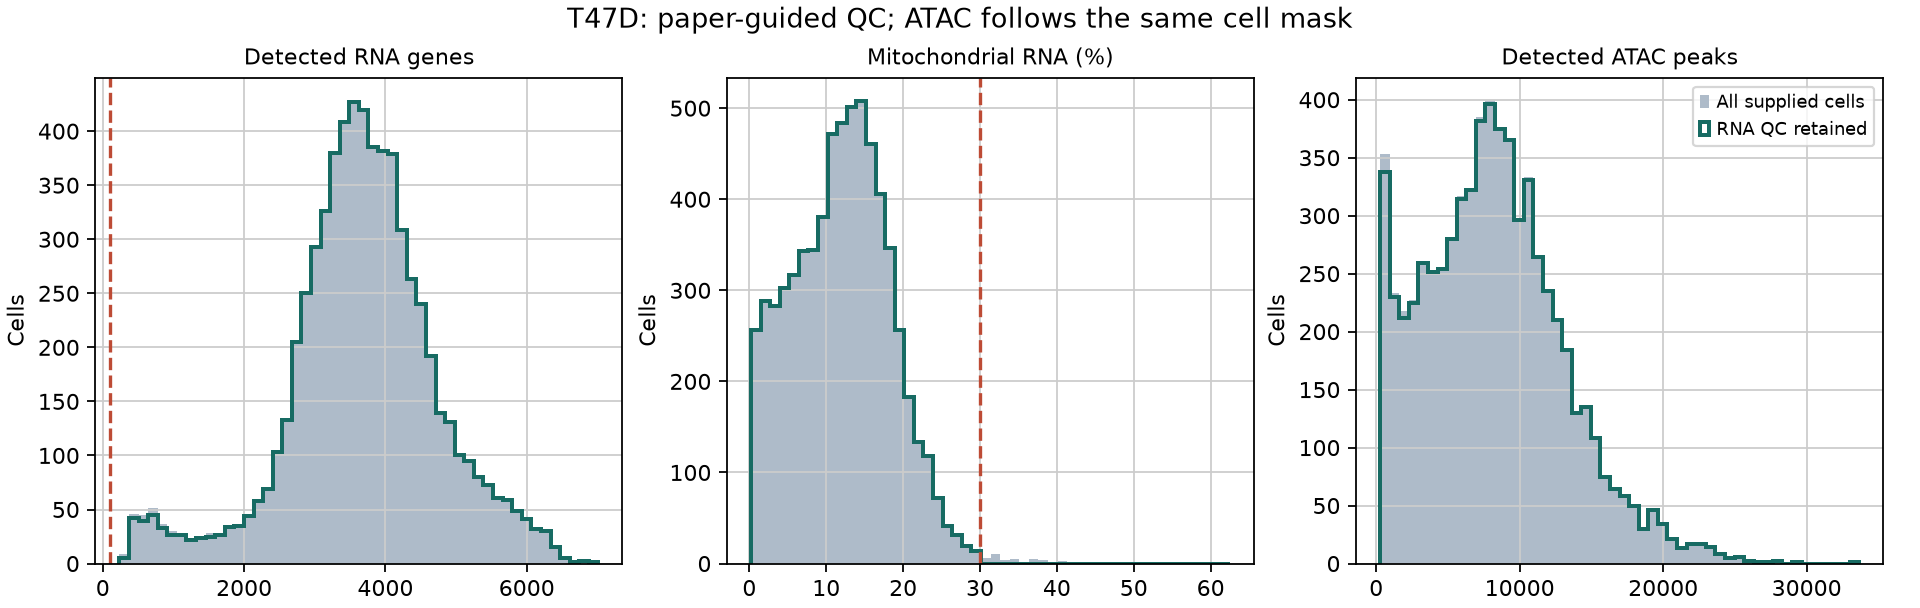

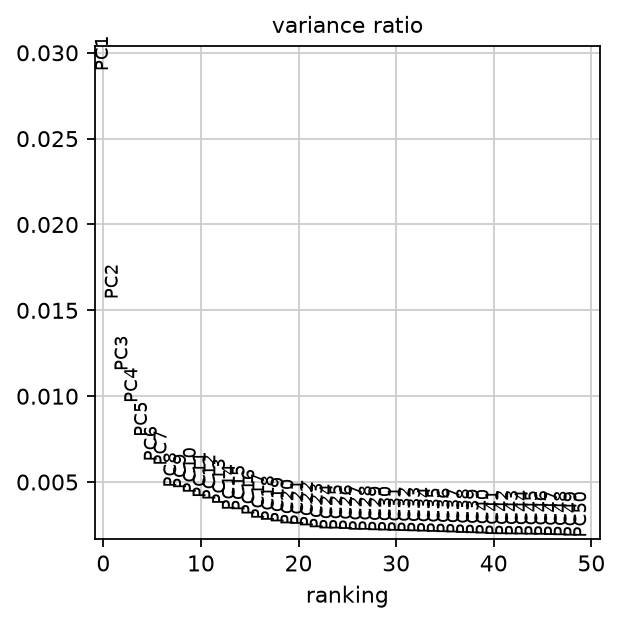

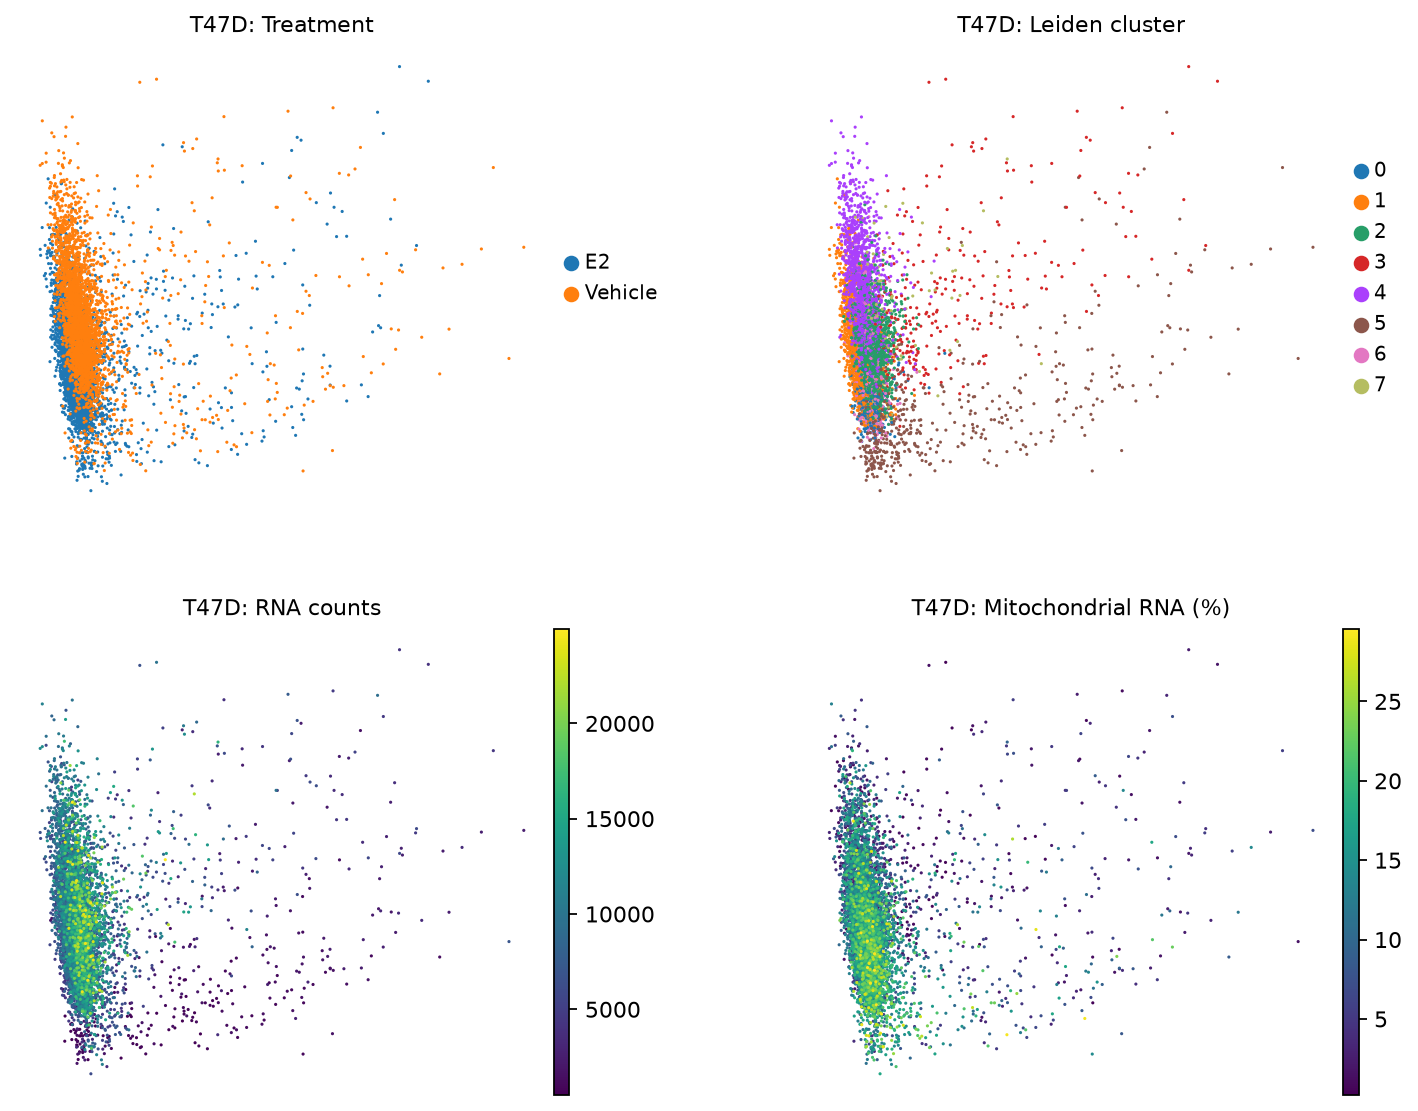

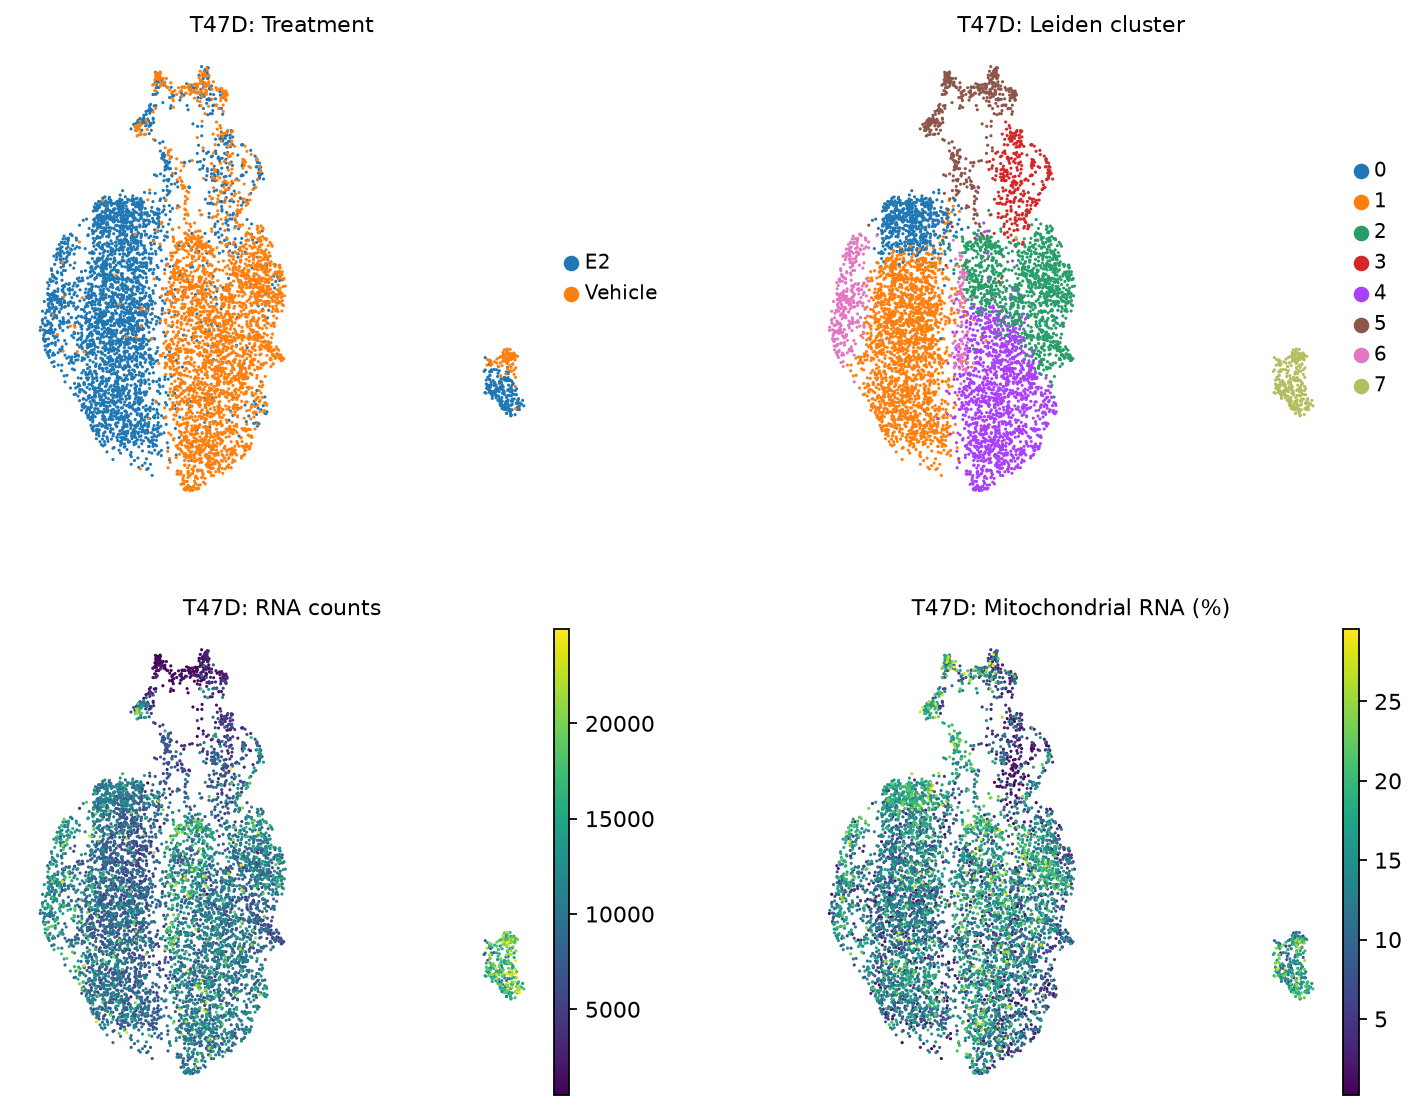

,leiden,E2,Vehicle
0,0,556,14
1,1,1896,28
2,2,105,1090
3,3,186,134
4,4,89,1309
5,5,229,223
6,6,317,115
7,7,187,84


In [9]:
print(json.dumps(report["cell_lines"]["T47D"],indent=2))
for suffix in ("paper_qc","pca_variance","rna_pca","rna_umap"):
    display(Image(filename=str(RESULTS_DIR/"figures"/f"T47D_{suffix}.png")))
display(pd.read_csv(RESULTS_DIR/"tables"/"T47D_cluster_treatment_counts.tsv",sep="\t"))

## 7. Save the combined report

In [10]:
(RESULTS_DIR/"tables"/"paper_qc_summary.json").write_text(json.dumps(report,indent=2)+"\n")
summary = pd.DataFrame({
    line: {"cells_before":v["cells_before"],"cells_after":v["cells_after"],
           "genes_after":v["genes_after"],"atac_peaks_after":v["atac_peaks_after"],
           "hvgs":v["visualization"]["n_hvgs"],"clusters":v["visualization"]["n_clusters"]}
    for line,v in report["cell_lines"].items()}).T
display(summary)

,cells_before,cells_after,genes_after,atac_peaks_after,hvgs,clusters
MCF7,6438,6019,25105,206167,2000,9
T47D,6615,6562,26320,206167,2000,8


## 8. Read the plots cautiously
- Compare treatment, clusters, RNA depth and mitochondrial fraction on the same embedding.
- Cluster numbers are arbitrary and are not comparable across independently fitted cell lines.
- UMAP separation is not statistical evidence of treatment effects or prediction accuracy.
- This fit uses the full retained cohort for description. Future prediction must refit
  feature selection, scaling and embeddings on training data.
- All 206,167 ATAC peaks are retained. No invented fragment/TSS/FRiP/doublet cutoffs.
- The scMKL paper states 24-hour treatment; the original study states 48 hours.
  Metadata do not resolve this. Treatment labels remain unchanged.
- This uses the stated QC thresholds plus exploratory visualization, not an exact
  reproduction of the paper's post-QC cells or figures.

See QC_PREPROCESSING.md for provenance and local validation. Review these outputs before
differential expression or any cell-state annotation.